# GreenCampus AI – Electricity Consumption Prediction

## 1. Introduction

This notebook develops a machine-learning model to predict
electricity consumption using campus activity and environmental
features.

Random Forest Regression is used for the prediction task.

#### Import libraries

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#### Load the cleaned dataset

In [10]:
df = pd.read_csv("C:/Users/Urja Chauhan/PycharmProjects/PythonProject/cleaned_campus_sustainability_data.csv")

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Building,Building_Type,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Temperature_C,Working_Day,Event_Day
0,2025-07-01,Block A,Academic,444,1437.09,8384.17,47.61,28.0,Yes,No
1,2025-07-01,Block B,Academic,269,1091.78,4583.04,23.77,28.0,Yes,No
2,2025-07-01,Block C,Laboratory,186,707.71,3556.96,22.42,28.0,Yes,No
3,2025-07-01,Library,Library,230,760.70,4039.62,24.38,28.0,Yes,No
4,2025-07-01,Hostel,Hostel,555,1679.32,9611.07,54.21,28.0,Yes,No


## 2. Features and Target Variable

#### Create useful features

In [11]:
df["Month"] = df["Date"].dt.month
df["Day_of_Week"] = df["Date"].dt.dayofweek

In [12]:
df["Working_Day_Num"] = df["Working_Day"].map({ "Yes": 1, "No": 0 })

df["Event_Day_Num"] = df["Event_Day"].map({ "Yes": 1, "No": 0 })

#### Convert Building into numerical features

In [13]:
df_model = pd.get_dummies(df, columns=["Building", "Building_Type"], dtype=int)

In [14]:
df_model.columns

Index(['Date', 'Occupancy', 'Electricity_kWh', 'Water_Litres', 'Waste_kg',
       'Temperature_C', 'Working_Day', 'Event_Day', 'Month', 'Day_of_Week',
       'Working_Day_Num', 'Event_Day_Num', 'Building_Block A',
       'Building_Block B', 'Building_Block C', 'Building_Hostel',
       'Building_Library', 'Building_Type_Academic', 'Building_Type_Hostel',
       'Building_Type_Laboratory', 'Building_Type_Library'],
      dtype='object')

#### Select input features

In [15]:
features = ["Occupancy", "Water_Litres", "Waste_kg", "Temperature_C", "Month", "Day_of_Week", "Working_Day_Num", "Event_Day_Num"]

In [16]:
#Create  features directly from the columns that actually exist
features = [ col for col in df_model.columns if col != "Electricity_kWh"]

#Remove duplicates column names from the feature list
features = list(dict.fromkeys(features))

print("Features:")
print(features)
print("Number of features:", len(features))

Features:
['Date', 'Occupancy', 'Water_Litres', 'Waste_kg', 'Temperature_C', 'Working_Day', 'Event_Day', 'Month', 'Day_of_Week', 'Working_Day_Num', 'Event_Day_Num', 'Building_Block A', 'Building_Block B', 'Building_Block C', 'Building_Hostel', 'Building_Library', 'Building_Type_Academic', 'Building_Type_Hostel', 'Building_Type_Laboratory', 'Building_Type_Library']
Number of features: 20


In [17]:
X = df_model[features]
y = df_model["Electricity_kWh"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1825, 20)
y shape: (1825,)


## 3. Data Preparation

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [19]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1460
Testing records: 365


## 4. Training and Testing Data

In [20]:
print(df_model.columns.tolist())

['Date', 'Occupancy', 'Electricity_kWh', 'Water_Litres', 'Waste_kg', 'Temperature_C', 'Working_Day', 'Event_Day', 'Month', 'Day_of_Week', 'Working_Day_Num', 'Event_Day_Num', 'Building_Block A', 'Building_Block B', 'Building_Block C', 'Building_Hostel', 'Building_Library', 'Building_Type_Academic', 'Building_Type_Hostel', 'Building_Type_Laboratory', 'Building_Type_Library']


In [21]:
X = df_model.drop(columns=["Electricity_kWh"])

In [22]:
print(df_model.columns.tolist())

['Date', 'Occupancy', 'Electricity_kWh', 'Water_Litres', 'Waste_kg', 'Temperature_C', 'Working_Day', 'Event_Day', 'Month', 'Day_of_Week', 'Working_Day_Num', 'Event_Day_Num', 'Building_Block A', 'Building_Block B', 'Building_Block C', 'Building_Hostel', 'Building_Library', 'Building_Type_Academic', 'Building_Type_Hostel', 'Building_Type_Laboratory', 'Building_Type_Library']


In [23]:
# Target
y = pd.to_numeric(df_model["Electricity_kWh"], errors="coerce")

# Features
X = df_model.drop(columns=["Electricity_kWh"]).copy()

# Convert Date into useful numerical features
if "Date" in X.columns:
    X["Date"] = pd.to_datetime(X["Date"], errors="coerce")
    X["Year"] = X["Date"].dt.year
    X["Month"] = X["Date"].dt.month
    X["Day"] = X["Date"].dt.day
    X["DayOfWeek"] = X["Date"].dt.dayofweek
    X = X.drop(columns=["Date"])

# Convert categorical/text columns into numbers
X = pd.get_dummies(X, drop_first=True)

# Make sure all feature values are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove rows with missing values
data = pd.concat([X, y.rename("Electricity_kWh")], axis=1).dropna()

X = data.drop(columns=["Electricity_kWh"])
y = data["Electricity_kWh"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

Training records: 1460
Testing records: 365
Number of features: 22


## 5. Random Forest Regression Model

In [24]:
from sklearn.ensemble import (RandomForestRegressor)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## 6. Model Training

In [25]:
y_pred = model.predict(X_test)

In [26]:
prediction_comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
prediction_comparison.head(10)

,Actual,Predicted
0,1431.91,1418.2209
1,1048.17,979.7306
2,839.04,708.1695
3,809.68,841.2761
4,1375.23,1321.6699
5,1738.95,1672.6518
6,1585.92,1689.6493
7,1704.35,1677.1025
8,911.39,916.4445
9,665.00,707.8482


## 7. Electricity Consumption Prediction

In [34]:
# Save prediction results

test_results = X_test.copy()

# Add actual values
test_results["Electricity_kwh"] = y_test

# Add predicted values
test_results["Predicted_Electricity_kwh"] = y_pred

# Calculate prediction error
test_results["Prediction_Error"] = (
    test_results["Electricity_kwh"]
    - test_results["Predicted_Electricity_kwh"]
)

print("Prediction results saved successfully!")
print(test_results.head())

Prediction results saved successfully!
      Occupancy  Water_Litres  Waste_kg  Temperature_C  Month  Day_of_Week  \
555         418       7481.49     44.20           26.6     10            0   
1744        160       1906.55     15.20           30.4      6            6   
297         184       3137.34     19.69           29.0      8            4   
733         246       4775.29     19.16           26.5     11            0   
910         424       7494.27     44.51           19.7     12            1   

      Working_Day_Num  Event_Day_Num  Building_Block A  Building_Block B  ...  \
555                 1              0                 1                 0  ...   
1744                0              0                 0                 0  ...   
297                 1              0                 0                 0  ...   
733                 1              0                 0                 0  ...   
910                 1              0                 1                 0  ...   

     

In [35]:
test_results.to_csv("C:/Users/Urja Chauhan/PycharmProjects/PythonProject/electricity_prediction_results.csv", index=False)

#### Creating a simple prediction insight

In [36]:
average_error = test_results["Prediction_Error"].abs().mean()

print("Average absolute prediction error:", round(average_error, 2), "kWh")

Average absolute prediction error: 66.6 kWh


## 8. Model Evaluation

In [27]:
mae = mean_absolute_error(y_test, y_pred)

In [28]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [29]:
r2 = r2_score(y_test, y_pred)

In [30]:
print("Mean absolute error:", round(mae, 2))
print("Root mean squared error:", round(rmse, 2))
print("R2 score:", round(r2,3))

Mean absolute error: 66.6
Root mean squared error: 86.5
R2 score: 0.961


## 9. Actual vs Predicted Electricity Consumption

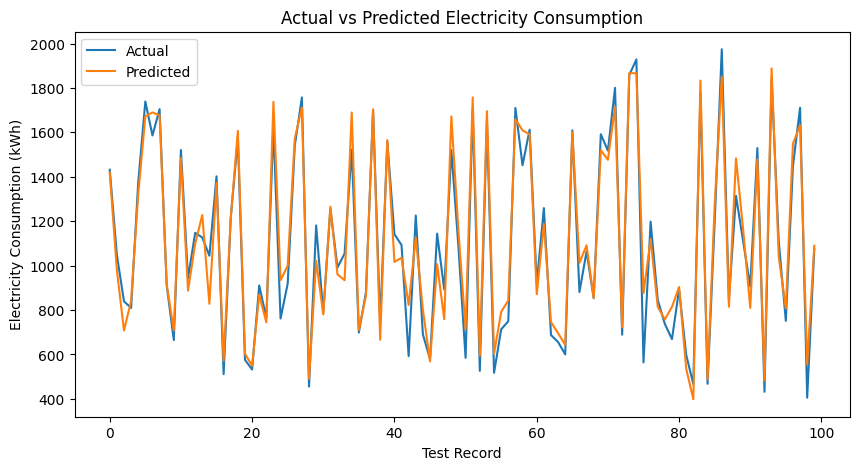

In [38]:
plt.figure(figsize=(10,5))

plt.plot(y_test.values[:100], label="Actual")

plt.plot(y_pred[:100], label="Predicted")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Record")
plt.ylabel("Electricity Consumption (kWh)")
plt.legend()
plt.show()

## 10. Feature Importance

In [32]:
importance = pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_})
importance = importance.sort_values("Importance", ascending=False)
importance.head(10)

,Feature,Importance
0,Occupancy,0.847507
3,Temperature_C,0.040420
11,Building_Hostel,0.023233
13,Building_Type_Academic,0.022539
14,Building_Type_Hostel,0.016799
8,Building_Block A,0.008768
1,Water_Litres,0.006521
2,Waste_kg,0.005641
9,Building_Block B,0.005611
10,Building_Block C,0.004898


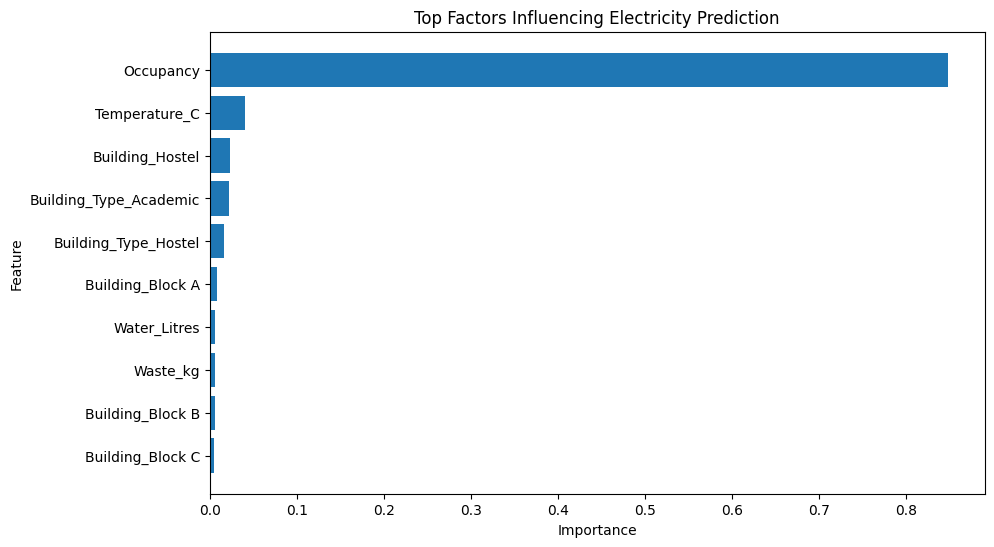

In [33]:
top_features = importance.head(10)

plt.figure(figsize=(10,6))

plt.barh(top_features["Feature"], top_features["Importance"])

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Factors Influencing Electricity Prediction")

plt.gca().invert_yaxis()
plt.show()

## 11. Prediction Summary

The prediction model provides an estimate of electricity consumption
based on the available campus and environmental features.

The model results should be interpreted according to the evaluation
metrics obtained from the test data.